# 02 Models

- XGBoost on the 16 features of the current payment
- LSTM on the last 7 payments of the customer (catches sequences like several growing transfers to new people). LSTM/Dense run on the Telum II NNPA via ibm-zdnn-plugin.

Both plus the rules give one risk score. Two thresholds: review (ask customer to confirm) and pause (hold payment, email trusted contact).

In [1]:
import os, sys, time, json, platform
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd().parent / "safepause").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from safepause import config
print("project:", ROOT, "| machine:", platform.machine(), "| CPUs:", os.cpu_count())

project: /home/ibm-user/shared/safepause | machine: s390x | CPUs: 3


In [2]:
from safepause.features import FEATURES, gather_sequences
from safepause.scorer import rule_matrix, combine, build_seq_model
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
d = np.load(config.DATASET_NPZ)
X, y, prev_idx, amount = d["X"], d["y"], d["prev_idx"], d["amount"]
vs, ts_ = int(d["val_start"]), int(d["test_start"])
tr, va, te = np.arange(vs), np.arange(vs, ts_), np.arange(ts_, len(X))
print(f"train {len(tr):,} ({y[tr].sum()} fraud) | val {len(va):,} ({y[va].sum()}) | test {len(te):,} ({y[te].sum()})")

train 179,892 (189 fraud) | val 29,483 (26) | test 36,489 (56)


## XGBoost

In [3]:
import xgboost as xgb
pos = y[tr].sum(); spw = (len(tr) - pos) / max(pos, 1)
dtr = xgb.DMatrix(X[tr], label=y[tr], feature_names=FEATURES)
dva = xgb.DMatrix(X[va], label=y[va], feature_names=FEATURES)
# few fraud cases -> shallow trees, strong regularisation
params = {"objective": "binary:logistic", "eval_metric": "aucpr", "tree_method": "hist",
          "max_depth": 4, "eta": 0.05, "subsample": 0.8, "colsample_bytree": 0.8,
          "min_child_weight": 3, "lambda": 5, "scale_pos_weight": min(spw, 30), "nthread": os.cpu_count()}
t0 = time.perf_counter()
booster = xgb.train(params, dtr, num_boost_round=800, evals=[(dva, "val")],
                    early_stopping_rounds=150, verbose_eval=100)
n_rounds = max(booster.best_iteration + 1, 200)   # val has only a few frauds, don't stop too early
booster = xgb.train(params, dtr, num_boost_round=n_rounds)
print(f"trained in {time.perf_counter()-t0:.0f}s, {n_rounds} rounds")
px_va = booster.inplace_predict(X[va]); px_te = booster.inplace_predict(X[te])
print("val PR-AUC %.3f" % average_precision_score(y[va], px_va))

[0]	val-aucpr:0.01602


[100]	val-aucpr:0.03316


[200]	val-aucpr:0.03897


[210]	val-aucpr:0.03850


trained in 2s, 200 rounds
val PR-AUC 0.046


## LSTM on NNPA

In [4]:
import importlib.metadata, glob
import tensorflow as tf
try:
    print("ibm-zdnn-plugin:", importlib.metadata.version("ibm-zdnn-plugin"))
except Exception:
    print("ibm-zdnn-plugin: not installed (running off-platform?)")
print("zDNN TF kernels:", glob.glob("/opt/venv/lib*/python3*/site-packages/tensorflow/core/kernels/_z_ops.so") or "not found")
print("TensorFlow", tf.__version__, tf.config.list_physical_devices())

ibm-zdnn-plugin: 2.3.0
zDNN TF kernels: ['/opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so', '/opt/venv/lib64/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so']
TensorFlow 2.18.1 [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [5]:
rng = np.random.default_rng(42)
fraud_tr = tr[y[tr] == 1]
normal_tr = rng.choice(tr[y[tr] == 0], size=min(len(tr) - len(fraud_tr), 15 * len(fraud_tr)), replace=False)
idx = rng.permutation(np.concatenate([fraud_tr, normal_tr]))
S_tr = gather_sequences(X, prev_idx, idx); y_tr = y[idx]
S_va = gather_sequences(X, prev_idx, va)
print("training sequences:", S_tr.shape, "fraud share %.1f%%" % (y_tr.mean() * 100))
seq_model = build_seq_model(norm_data=S_tr.reshape(-1, S_tr.shape[-1]))
seq_model.summary()
t0 = time.perf_counter()
hist = seq_model.fit(S_tr, y_tr, epochs=15, batch_size=256, validation_data=(S_va, y[va]),
                     class_weight={0: 1.0, 1: 3.0}, verbose=2)
print(f"trained in {time.perf_counter()-t0:.0f}s")

training sequences: (3024, 7, 21) fraud share 6.2%


Model: "safepause_seq"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ payments (InputLayer)                │ (None, 7, 21)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ norm (Normalization)                 │ (None, 7, 21)               │              43 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          22,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ risk (Dense)                         │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,172 (94.43 KB)

 Trainable params: 24,129 (94.25 KB)

...

Epoch 14/15


12/12 - 0s - 23ms/step - loss: 0.0535 - pr_auc: 0.9779 - val_loss: 0.0993 - val_pr_auc: 0.0059


Epoch 15/15


12/12 - 0s - 22ms/step - loss: 0.0523 - pr_auc: 0.9730 - val_loss: 0.0908 - val_pr_auc: 0.0062


trained in 7s


In [6]:
@tf.function(input_signature=[tf.TensorSpec([None, *S_va.shape[1:]], tf.float32)])
def seq_predict(s): return seq_model(s, training=False)
def predict_seq(rows, bs=4096):
    return np.concatenate([seq_predict(gather_sequences(X, prev_idx, rows[i:i+bs])).numpy().ravel()
                           for i in range(0, len(rows), bs)])
ps_va, ps_te = predict_seq(va), predict_seq(te)
print("LSTM val PR-AUC %.3f" % average_precision_score(y[va], ps_va))

LSTM val PR-AUC 0.006


## Combine + thresholds (validation set only)

In [7]:
n_va, n_te = rule_matrix(X[va]).sum(1), rule_matrix(X[te]).sum(1)
best = None
for w in np.linspace(0.3, 0.8, 6):  # keep both models
    for boost in (0.03, 0.05, 0.1):
        m = {"w_xgb": w, "rule_boost": boost}
        ap_ = average_precision_score(y[va], combine(px_va, ps_va, n_va, m))
        if best is None or ap_ > best[0]: best = (ap_, w, boost)
meta = {"w_xgb": float(best[1]), "rule_boost": float(best[2])}
r_va = combine(px_va, ps_va, n_va, meta)
p, r, t = precision_recall_curve(y[va], r_va)
f1 = 2 * p * r / (p + r + 1e-9)
t_pause = float(t[np.argmax(f1[:-1])])
# review: catch >=85% of fraud but ask at most ~3% of customers
cand = [tt for pp, rr, tt in zip(p[:-1], r[:-1], t) if rr >= 0.85 and (r_va >= tt).mean() <= 0.03]
t_review = float(max(cand)) if cand else float(np.quantile(r_va, 0.97))
t_review = min(t_review, t_pause * 0.9)
meta.update({"t_pause": t_pause, "t_review": t_review, "features": FEATURES, "seq_len": config.SEQ_LEN})
print(f"weights xgb={meta['w_xgb']:.1f} lstm={1-meta['w_xgb']:.1f} rule_boost={meta['rule_boost']} | "
      f"pause >= {t_pause:.3f} | review >= {t_review:.3f}")

weights xgb=0.8 lstm=0.2 rule_boost=0.05 | pause >= 0.410 | review >= 0.100


## Test period results

In [8]:
r_te = combine(px_te, ps_te, n_te, meta)
def report(name, s, thr):
    pred = s >= thr
    tp = (pred & (y[te] == 1)).sum(); fp = (pred & (y[te] == 0)).sum(); fn = ((~pred) & (y[te] == 1)).sum()
    return {"model": name, "PR-AUC": average_precision_score(y[te], s), "ROC-AUC": roc_auc_score(y[te], s),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "alert rate %": pred.mean() * 100}
def best_thr(s_va):
    p, r, t = precision_recall_curve(y[va], s_va); f = 2*p*r/(p+r+1e-9); return t[np.argmax(f[:-1])]
res = pd.DataFrame([report("XGBoost only", px_te, best_thr(px_va)),
                    report("LSTM only (NNPA)", ps_te, best_thr(ps_va)),
                    report("SafePause hybrid: PAUSE", r_te, t_pause),
                    report("SafePause hybrid: REVIEW or PAUSE", r_te, t_review)]).round(3)
display(res)
dec_pause = r_te >= t_pause
saved = np.abs(amount[te])[dec_pause & (y[te] == 1)].sum()
print(f"fraud money stopped by PAUSE in test period: ${saved:,.0f} of ${np.abs(amount[te])[y[te]==1].sum():,.0f}")
res.to_csv(config.ARTIFACTS / "results_test.csv", index=False)

,model,PR-AUC,ROC-AUC,precision,recall,alert rate %
0,XGBoost only,0.061,0.895,0.167,0.018,0.016
1,LSTM only (NNPA),0.017,0.671,0.020,0.125,0.937
2,SafePause hybrid: PAUSE,0.057,0.836,0.136,0.054,0.060
3,SafePause hybrid: REVIEW or PAUSE,0.057,0.836,0.017,0.321,2.875


fraud money stopped by PAUSE in test period: $204 of $3,965


## Fraud attacks caught
In the data fraud comes in bursts (a stolen card is used several times in a few days). Once one payment of a burst is paused the bank calls the customer and blocks the rest, so we also count how many attacks were stopped and how early.

In [9]:
raw = pd.read_csv(config.STREAM_CSV, usecols=["user", "ts", "amount", "is_fraud"])
raw["ts"] = pd.to_datetime(raw.ts)
flag_review = r_te >= meta["t_review"]
flag_pause = r_te >= meta["t_pause"]
fr = raw[raw.is_fraud == 1].copy()
fr["review"] = flag_review[fr.index]; fr["pause"] = flag_pause[fr.index]
fr = fr.sort_values(["user", "ts"])
fr["episode"] = ((fr.user != fr.user.shift()) | (fr.ts - fr.ts.shift() > pd.Timedelta(days=3))).cumsum()
rows = []
for e, g in fr.groupby("episode"):
    hit = np.flatnonzero(g.review.to_numpy())
    first = hit[0] if len(hit) else None
    rows.append({"episode": e, "payments": len(g), "caught": first is not None,
                 "caught_at_payment": None if first is None else first + 1,
                 "money_total": g.amount.abs().sum(),
                 "money_after_catch": 0 if first is None else g.amount.abs().iloc[first:].sum()})
ep = pd.DataFrame(rows)
display(ep)
print(f"attacks in test period: {len(ep)} | stopped (review or pause): {ep.caught.sum()} "
      f"({ep.caught.mean()*100:.0f}%) | median payment number when caught: {ep.caught_at_payment.median()}")
print(f"fraud money that would be blocked after the first alert: ${ep.money_after_catch.sum():,.0f} of ${ep.money_total.sum():,.0f}")
print(f"normal payments flagged for review: {(flag_review & (y[te]==0)).mean()*100:.2f}% | paused: {(flag_pause & (y[te]==0)).mean()*100:.2f}%")
ep.to_csv(config.ARTIFACTS / "attacks_test.csv", index=False)

,episode,payments,caught,caught_at_payment,money_total,money_after_catch
0,1,2,False,NaN,502.22,0.00
1,2,3,False,NaN,64.69,0.00
2,3,4,False,NaN,287.51,0.00
3,4,1,False,NaN,49.31,0.00
4,5,11,True,2.0,704.70,698.66
5,6,8,True,7.0,423.35,97.73
6,7,2,False,NaN,45.16,0.00
7,8,4,False,NaN,459.18,0.00
8,9,1,False,NaN,39.79,0.00
9,10,2,False,NaN,58.63,0.00


attacks in test period: 17 | stopped (review or pause): 6 (35%) | median payment number when caught: 1.0
fraud money that would be blocked after the first alert: $1,677 of $3,965
normal payments flagged for review: 2.83% | paused: 0.05%


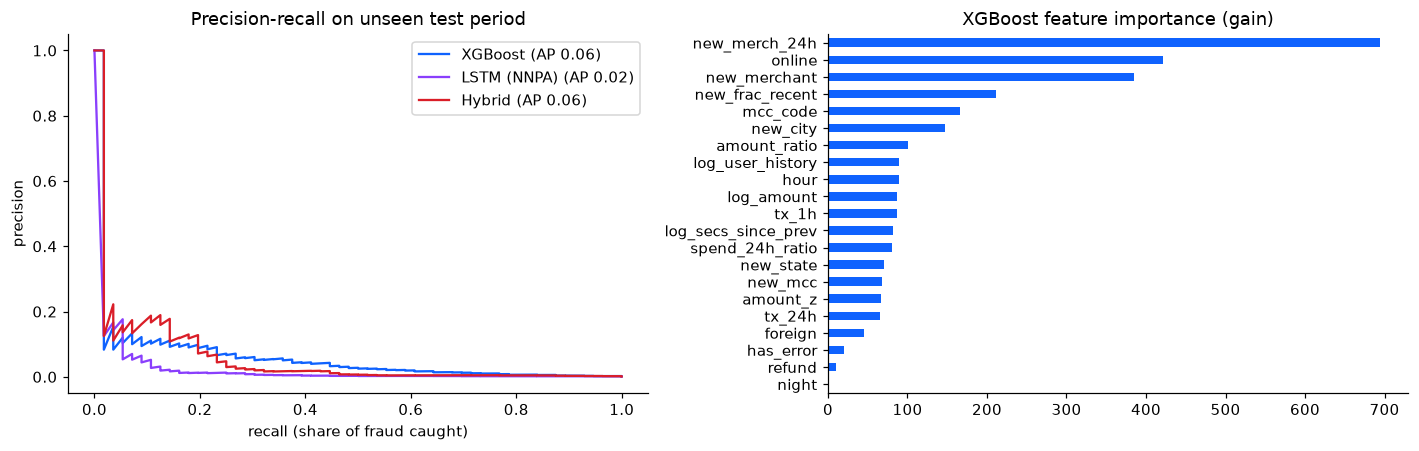

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, s, c in [("XGBoost", px_te, "#0f62fe"), ("LSTM (NNPA)", ps_te, "#8a3ffc"), ("Hybrid", r_te, "#da1e28")]:
    p, r, _ = precision_recall_curve(y[te], s)
    ax[0].plot(r, p, label=f"{name} (AP {average_precision_score(y[te], s):.2f})", color=c)
ax[0].set_xlabel("recall (share of fraud caught)"); ax[0].set_ylabel("precision"); ax[0].legend(); ax[0].set_title("Precision-recall on unseen test period")
imp = pd.Series(booster.get_score(importance_type="gain")).reindex(FEATURES).fillna(0).sort_values()
imp.plot.barh(ax=ax[1], color="#0f62fe"); ax[1].set_title("XGBoost feature importance (gain)")
plt.tight_layout(); plt.savefig(config.FIGURES / "02_results.png", bbox_inches="tight"); plt.show()

## Save models

In [11]:
booster.save_model(str(config.MODELS / "xgb.json"))
seq_model.save(config.MODELS / "seq_model.keras")
json.dump(meta, open(config.MODELS / "meta.json", "w"), indent=2)
print("saved to", config.MODELS, os.listdir(config.MODELS))

saved to /home/ibm-user/shared/safepause/artifacts/models ['xgb.json', 'seq_model.keras', 'meta.json']
